# Assignment 4 — N-gram Language Models on IndicCorp v2 (Hindi)

**Corpus:** same Hindi (`hin_Deva`) IndicCorp v2 corpus of **1,000,000 sentences** built in the
previous assignment, using the **same train / dev / test splits** (dev and test = 1000
length-stratified sentences each; the rest is training data).

This notebook:

1. Reloads the exact train / dev / test splits saved earlier (`data/train_pool.txt`,
   `data/dev.txt`, `data/test.txt`). If those files aren't present, it rebuilds them with the
   identical procedure used in the tokenization assignment (streaming IndicCorp v2, sentence
   tokenizing, length-stratified dev/test sampling) so this notebook is self-contained.
2. Builds **unigram, bigram, trigram, and quadgram** language models (`N = 1, 2, 3, 4`).
3. For each `N`, computes probabilities under **five settings**:
   1. **Unsmoothed** (raw counts / MLE)
   2. **Add-1 (Laplace) smoothing**
   3. **Add-k smoothing** (`0 < k < 1`, we use `k = 0.1`)
   4. **Interpolated smoothing** (linear interpolation of the raw n-gram MLE with lower-order
      models, back down to the uniform/unigram level — for unigrams this reduces to
      `P_smooth(w) = λP(w) + (1-λ)/V`)
   5. **Kneser-Ney smoothing** (discount `d = 0.75`, with the standard continuation-probability
      recursion down to unigrams)
4. Evaluates every `(N, smoothing)` combination by **perplexity on train / dev / test**.
5. Compares all models in summary tables and plots.

> **Note on runtime:** this notebook is provided as the assignment deliverable (code only) and is
> **not executed here**. Cells are written to run top-to-bottom once you have the corpus files
> from the previous assignment (or let Section 1 regenerate them). Training quadgram models with
> Kneser-Ney on 1M sentences of real text can take a while — see the `SAMPLE_TRAIN_SIZE` note in
> Section 1 if you want a faster sanity-check pass before running on the full data.


## 0. Setup — imports and config

In [14]:

import os
import re
import math
import random
import itertools
from pathlib import Path
from collections import Counter, defaultdict

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from tqdm.auto import tqdm

random.seed(42)
np.random.seed(42)

DATA_DIR = Path("data")
DATA_DIR.mkdir(exist_ok=True)

# Special tokens for sentence boundaries / unknown words
BOS = "<s>"
EOS = "</s>"
UNK = "<unk>"

# N-gram orders required by the assignment
N_VALUES = [1, 2, 3, 4]
NGRAM_NAMES = {1: "unigram", 2: "bigram", 3: "trigram", 4: "quadgram"}

# Smoothing hyperparameters
ADD_K = 0.1            # 0 < k < 1, for add-k smoothing
INTERP_LAMBDA = 0.7    # interpolation constant (lambda) used throughout
KN_DISCOUNT = 0.75     # Kneser-Ney discount d

# If you just want a fast sanity-check run before committing to the full 1M-sentence
# training set, set SAMPLE_TRAIN_SIZE to e.g. 100_000. Set to None to use the FULL train
# split (matches "same corpus ... 1000000 sentences" from the assignment).
SAMPLE_TRAIN_SIZE = 100_000


## 1. Load the same train / dev / test splits from the previous assignment

We reuse the exact files written by the tokenization assignment:

- `data/train_pool.txt` — training sentences (everything not selected for dev/test)
- `data/dev.txt` — 1000 length-stratified development sentences
- `data/test.txt` — 1000 length-stratified test sentences

If these files are not found (e.g. running in a fresh environment), the cell below **rebuilds
them from scratch using the identical pipeline** (stream Hindi paragraphs from IndicCorp v2 →
sentence-tokenize with `indic-nlp-library` → length-stratified dev/test sampling), so the rest of
this notebook still works unmodified.


In [15]:

train_pool_path = DATA_DIR / "train_pool.txt"
dev_path        = DATA_DIR / "dev.txt"
test_path       = DATA_DIR / "test.txt"

def read_lines(path):
    with open(path, "r", encoding="utf-8") as f:
        return [line.rstrip("\n") for line in f if line.strip()]

if train_pool_path.exists() and dev_path.exists() and test_path.exists():
    print("Found existing splits from the previous assignment — loading them.")
    train_sentences = read_lines(train_pool_path)
    dev_sentences   = read_lines(dev_path)
    test_sentences  = read_lines(test_path)
else:
    print("Splits not found locally — rebuilding from IndicCorp v2 (same procedure as before).")

    # ---- 1a. Config (identical to the tokenization assignment) ----
    LANGUAGE_SPLIT = "hin_Deva"
    LANGUAGE_NAME  = "Hindi"
    LANG_ISO       = "hi"

    MAX_TRAIN_SIZE = 1_000_000
    DEV_SIZE       = 1_000
    TEST_SIZE      = 1_000
    TARGET_SENTENCES = MAX_TRAIN_SIZE + DEV_SIZE + TEST_SIZE
    PARAGRAPH_SAFETY_MARGIN = 1.4

    # ---- 1b. Stream raw paragraphs ----
    from datasets import load_dataset

    def stream_paragraphs(language_split, n_target):
        ds = load_dataset(
            "ai4bharat/IndicCorpV2",
            "indiccorp_v2",
            split=language_split,
            streaming=True,
        )
        paragraphs = []
        n_pull = int(n_target * PARAGRAPH_SAFETY_MARGIN)
        for ex in tqdm(ds, total=n_pull, desc=f"Streaming {language_split}"):
            text = ex["text"].strip()
            if text:
                paragraphs.append(text)
            if len(paragraphs) >= n_pull:
                break
        return paragraphs

    raw_paragraphs = stream_paragraphs(LANGUAGE_SPLIT, TARGET_SENTENCES)
    print(f"Pulled {len(raw_paragraphs):,} paragraphs for {LANGUAGE_NAME}")

    # ---- 1c. Sentence tokenization (indic-nlp-library, regex fallback) ----
    try:
        from indicnlp.tokenize import sentence_tokenize as indic_sent_tok
        HAVE_INDIC_NLP = True
        print("Using indic-nlp-library sentence tokenizer")
    except Exception as e:
        HAVE_INDIC_NLP = False
        print("indic-nlp-library unavailable, using regex fallback:", e)

    _SENT_SPLIT_RE = re.compile(r"(?<=[।॥.!?])\s+")

    def sentence_tokenize(paragraph, lang_iso="hi"):
        if HAVE_INDIC_NLP:
            try:
                sents = indic_sent_tok.sentence_split(paragraph, lang=lang_iso)
                sents = [s.strip() for s in sents if s.strip()]
                if sents:
                    return sents
            except Exception:
                pass
        sents = _SENT_SPLIT_RE.split(paragraph)
        return [s.strip() for s in sents if s.strip()]

    def clean_sentence(s):
        return re.sub(r"\s+", " ", s).strip()

    MIN_SENT_LEN_CHARS = 5
    MAX_SENT_LEN_CHARS = 800

    all_sentences = []
    seen = set()
    for para in tqdm(raw_paragraphs, desc="Sentence-tokenizing"):
        for sent in sentence_tokenize(para, LANG_ISO):
            sent = clean_sentence(sent)
            if not (MIN_SENT_LEN_CHARS <= len(sent) <= MAX_SENT_LEN_CHARS):
                continue
            if sent in seen:
                continue
            seen.add(sent)
            all_sentences.append(sent)
        if len(all_sentences) >= TARGET_SENTENCES:
            break

    print(f"Collected {len(all_sentences):,} unique sentences (target: {TARGET_SENTENCES:,})")

    # ---- 1d. Length-stratified train/dev/test split (identical procedure) ----
    def word_len(s):
        return len(s.split())

    lengths = np.array([word_len(s) for s in all_sentences])
    df = pd.DataFrame({"sentence": all_sentences, "length": lengths})

    N_BINS = 10
    df["bin"] = pd.qcut(df["length"], q=N_BINS, duplicates="drop")

    def stratified_sample(frame, n_total, n_bins_col="bin", seed=42):
        rng = np.random.RandomState(seed)
        bins = frame[n_bins_col].cat.categories
        picks = []
        bin_sizes = frame.groupby(n_bins_col, observed=True).size()
        proportions = bin_sizes / bin_sizes.sum()
        raw_alloc = proportions * n_total
        alloc = np.floor(raw_alloc).astype(int)
        shortfall = n_total - alloc.sum()
        remainder_order = (raw_alloc - alloc).sort_values(ascending=False).index
        for b in remainder_order[:shortfall]:
            alloc[b] += 1
        for b in bins:
            sub = frame[frame[n_bins_col] == b]
            k = min(alloc.get(b, 0), len(sub))
            chosen = sub.sample(n=k, random_state=seed)
            picks.append(chosen)
        sampled = pd.concat(picks).sample(frac=1.0, random_state=seed)
        remaining = frame.drop(sampled.index)
        return sampled, remaining

    test_df, pool_df = stratified_sample(df, TEST_SIZE, seed=42)
    dev_df,  pool_df = stratified_sample(pool_df, DEV_SIZE, seed=43)
    train_pool_df = pool_df.sample(frac=1.0, random_state=44).reset_index(drop=True)

    def write_lines(path, sentences):
        with open(path, "w", encoding="utf-8") as f:
            for s in sentences:
                f.write(s + "\n")

    write_lines(train_pool_path, train_pool_df["sentence"].tolist())
    write_lines(dev_path,        dev_df["sentence"].tolist())
    write_lines(test_path,       test_df["sentence"].tolist())

    train_sentences = train_pool_df["sentence"].tolist()
    dev_sentences   = dev_df["sentence"].tolist()
    test_sentences  = test_df["sentence"].tolist()

if SAMPLE_TRAIN_SIZE is not None:
    train_sentences = train_sentences[:SAMPLE_TRAIN_SIZE]

print(f"train: {len(train_sentences):,} | dev: {len(dev_sentences):,} | test: {len(test_sentences):,}")


Found existing splits from the previous assignment — loading them.
train: 100,000 | dev: 1,000 | test: 1,000


## 2. Preprocessing — tokenize, add sentence boundaries, handle unknown words

We word-tokenize (whitespace split, same granularity as the length-stratification step in the
previous assignment), pad every sentence with `N-1` beginning-of-sentence tokens `<s>` and one
end-of-sentence token `</s>` (padded independently for each order `N`, so a quadgram model gets 3
`<s>` tokens), and replace training words that occur exactly once with `<unk>` so the model has a
well-defined way to handle unseen words at test time.


In [16]:

def word_tokenize(sentence):
    return sentence.strip().split()

# ---- Build vocabulary from the training data, replacing hapax legomena with <unk> ----
train_token_lists_raw = [word_tokenize(s) for s in tqdm(train_sentences, desc="Tokenizing train")]

unigram_counts_raw = Counter(itertools.chain.from_iterable(train_token_lists_raw))
print(f"Raw training vocabulary (before <unk> collapsing): {len(unigram_counts_raw):,} word types")

VOCAB = {w for w, c in unigram_counts_raw.items() if c > 1}
VOCAB.add(UNK)
print(f"Vocabulary after replacing hapax legomena with <unk>: {len(VOCAB):,} word types")

def apply_unk(tokens, vocab=VOCAB):
    return [t if t in vocab else UNK for t in tokens]

train_token_lists = [apply_unk(toks) for toks in tqdm(train_token_lists_raw, desc="Applying <unk> (train)")]
dev_token_lists   = [apply_unk(word_tokenize(s)) for s in tqdm(dev_sentences,  desc="Tokenizing dev")]
test_token_lists  = [apply_unk(word_tokenize(s)) for s in tqdm(test_sentences, desc="Tokenizing test")]

V = len(VOCAB)  # vocabulary size used in all smoothing formulas below
print(f"\nFinal vocabulary size V = {V:,}")


Tokenizing train:   0%|          | 0/100000 [00:00<?, ?it/s]

Raw training vocabulary (before <unk> collapsing): 108,144 word types
Vocabulary after replacing hapax legomena with <unk>: 41,446 word types


Applying <unk> (train):   0%|          | 0/100000 [00:00<?, ?it/s]

Tokenizing dev:   0%|          | 0/1000 [00:00<?, ?it/s]

Tokenizing test:   0%|          | 0/1000 [00:00<?, ?it/s]


Final vocabulary size V = 41,446


In [17]:

def pad_sentence(tokens, n):
    # \"\"\"Pad a token list with (n-1) <s> tokens at the start and one </s> at the end,
    # as required for an order-n language model.\"\"\"
    return [BOS] * (n - 1) + tokens + [EOS]

def get_ngrams(tokens, n):
    # \"\"\"Yield all n-grams (as tuples) from an already-padded token list.\"\"\"
    return [tuple(tokens[i:i + n]) for i in range(len(tokens) - n + 1)]


## 3. Counting n-grams for every order N = 1, 2, 3, 4

For each order `n`, we need:

- `ngram_counts[n]` — counts of every n-gram `C(w_1, ..., w_n)`
- `context_counts[n]` — counts of every (n-1)-length context `C(w_1, ..., w_{n-1})`, needed as the
  denominator for conditional probabilities (for unigrams the "context" is the empty tuple, whose
  count is just the total number of tokens)

These raw counts are shared by **all five smoothing settings** for a given `N` — smoothing only
changes how we turn counts into probabilities, not how we count.


In [18]:

ngram_counts   = {}   # n -> Counter of n-grams
context_counts = {}   # n -> Counter of (n-1)-grams (contexts)

for n in N_VALUES:
    print(f"Counting {NGRAM_NAMES[n]}s (n={n}) ...")
    nc = Counter()
    cc = Counter()
    for toks in tqdm(train_token_lists, desc=f"  n={n}", leave=False):
        padded = pad_sentence(toks, n)
        for ng in get_ngrams(padded, n):
            nc[ng] += 1
            cc[ng[:-1]] += 1
    ngram_counts[n] = nc
    context_counts[n] = cc
    print(f"  -> {len(nc):,} distinct {n}-grams, {len(cc):,} distinct contexts")


Counting unigrams (n=1) ...


  n=1:   0%|          | 0/100000 [00:00<?, ?it/s]

  -> 41,447 distinct 1-grams, 1 distinct contexts
Counting bigrams (n=2) ...


  n=2:   0%|          | 0/100000 [00:00<?, ?it/s]

  -> 588,806 distinct 2-grams, 41,447 distinct contexts
Counting trigrams (n=3) ...


  n=3:   0%|          | 0/100000 [00:00<?, ?it/s]

  -> 1,267,345 distinct 3-grams, 583,916 distinct contexts
Counting quadgrams (n=4) ...


  n=4:   0%|          | 0/100000 [00:00<?, ?it/s]

  -> 1,589,859 distinct 4-grams, 1,237,568 distinct contexts


## 4. Smoothing methods

Each function below returns `P(w_n | w_1, ..., w_{n-1})` for a given order `n`, using only the
counts already computed in Section 3. Unigram probabilities are handled as a special case (empty
context) for every method.

### 4.1 Unsmoothed (MLE / raw counts)

$$P(w_n \mid w_1,\dots,w_{n-1}) = \frac{C(w_1,\dots,w_n)}{C(w_1,\dots,w_{n-1})}$$

Undefined (0/0) or zero-count n-grams get probability 0 — this is what makes unsmoothed models
assign **zero probability, hence infinite perplexity**, to any unseen n-gram, which we'll see
clearly in the results table.


In [19]:

def prob_unsmoothed(ngram, n):
    context = ngram[:-1]
    num = ngram_counts[n].get(ngram, 0)
    den = context_counts[n].get(context, 0) if n > 1 else sum(ngram_counts[1].values())
    if den == 0:
        return 0.0
    return num / den


### 4.2 Add-1 (Laplace) smoothing

$$P_{Laplace}(w_n \mid w_1,\dots,w_{n-1}) = \frac{C(w_1,\dots,w_n) + 1}{C(w_1,\dots,w_{n-1}) + V}$$


In [20]:

def prob_add1(ngram, n):
    context = ngram[:-1]
    num = ngram_counts[n].get(ngram, 0) + 1
    den_base = context_counts[n].get(context, 0) if n > 1 else sum(ngram_counts[1].values())
    den = den_base + V
    return num / den


### 4.3 Add-k smoothing ($0 < k < 1$)

Same as Laplace smoothing but with a fractional pseudo-count $k$ instead of 1, which is less
aggressive at flattening the distribution. We use $k = 0.1$ (see `ADD_K` in Section 0).

$$P_{add-k}(w_n \mid w_1,\dots,w_{n-1}) = \frac{C(w_1,\dots,w_n) + k}{C(w_1,\dots,w_{n-1}) + kV}$$


In [21]:

def prob_addk(ngram, n, k=ADD_K):
    context = ngram[:-1]
    num = ngram_counts[n].get(ngram, 0) + k
    den_base = context_counts[n].get(context, 0) if n > 1 else sum(ngram_counts[1].values())
    den = den_base + k * V
    return num / den


### 4.4 Interpolated smoothing

We linearly interpolate the raw (unsmoothed) order-`n` MLE estimate with the smoothed
lower-order (`n-1`) model, recursing down to the unigram level, where we use the formula given in
the assignment:

$$P_{smooth}(w_i) = \lambda P(w_i) + (1-\lambda)\frac{1}{V}$$

For `n > 1` we apply the same interpolation constant $\lambda$ at every level:

$$P_{interp}(w_n \mid w_1,\dots,w_{n-1}) = \lambda\, P_{MLE}(w_n \mid w_1,\dots,w_{n-1}) + (1-\lambda)\, P_{interp}(w_n \mid w_2,\dots,w_{n-1})$$

i.e. each order backs off to the (already-smoothed) next-lower order rather than to a flat
uniform distribution, so a trigram model implicitly blends trigram, bigram, and unigram evidence.


In [22]:

def prob_interp(ngram, n, lam=INTERP_LAMBDA):
    if n == 1:
        w = ngram[0]
        p_unigram_mle = ngram_counts[1].get(ngram, 0) / max(sum(ngram_counts[1].values()), 1)
        return lam * p_unigram_mle + (1 - lam) * (1.0 / V)
    else:
        context = ngram[:-1]
        num = ngram_counts[n].get(ngram, 0)
        den = context_counts[n].get(context, 0)
        p_mle_n = (num / den) if den > 0 else 0.0
        lower_ngram = ngram[1:]              # drop the oldest context word -> order n-1
        p_lower = prob_interp(lower_ngram, n - 1, lam)
        return lam * p_mle_n + (1 - lam) * p_lower


### 4.5 Kneser-Ney smoothing ($d = 0.75$)

Standard interpolated Kneser-Ney. For the highest order we discount raw counts by a fixed
$d \in (0,1)$ and redistribute the "saved" probability mass, weighted by the number of distinct
continuations, to the lower-order model:

$$P_{KN}(w_n \mid w_1,\dots,w_{n-1}) = \frac{\max(C(w_1,\dots,w_n) - d,\ 0)}{C(w_1,\dots,w_{n-1})} + \lambda(w_1,\dots,w_{n-1})\, P_{KN}(w_n \mid w_2,\dots,w_{n-1})$$

where the backoff weight is

$$\lambda(w_1,\dots,w_{n-1}) = \frac{d}{C(w_1,\dots,w_{n-1})}\, |\{w : C(w_1,\dots,w_{n-1},w) > 0\}|$$

At the unigram level, instead of raw unigram frequency we use the **continuation probability** —
how many *distinct* bigram contexts each word appears in as the final word, normalized by the
total number of distinct bigram types — which is the key idea that makes Kneser-Ney different
from ordinary interpolation (a word like "the" is frequent, but "Francisco" should only get a
high unigram backoff probability because it follows *many different* words, not because it's
frequent overall).


In [23]:

# ---- Continuation-count statistics needed for the Kneser-Ney unigram base distribution ----
# continuation_count[w] = number of distinct bigram contexts (w_{i-1}) that precede w
bigram_counts_for_kn = ngram_counts[2]

continuation_count = defaultdict(set)
for (w_prev, w), c in bigram_counts_for_kn.items():
    continuation_count[w].add(w_prev)
continuation_count = {w: len(ctxs) for w, ctxs in continuation_count.items()}
total_distinct_bigrams = len(bigram_counts_for_kn)

def p_continuation(w):
    # \"\"\"Kneser-Ney unigram base distribution P_continuation(w).\"\"\"
    return continuation_count.get(w, 0) / max(total_distinct_bigrams, 1)

def prob_kneser_ney(ngram, n, d=KN_DISCOUNT):
    if n == 1:
        # Backoff floor: continuation probability, with a tiny epsilon fallback for words
        # that never appear as a bigram continuation (e.g. only ever sentence-initial).
        p = p_continuation(ngram[0])
        return p if p > 0 else 1.0 / V
    context = ngram[:-1]
    context_count = context_counts[n].get(context, 0)
    if context_count == 0:
        # Unseen context: fall back entirely to the lower-order model.
        return prob_kneser_ney(ngram[1:], n - 1, d)
    raw_count = ngram_counts[n].get(ngram, 0)
    discounted = max(raw_count - d, 0) / context_count
    # number of distinct word types w that complete this context (for the backoff weight)
    n_distinct_continuations = sum(
        1 for ng in ngram_counts[n] if ng[:-1] == context
    )
    # NOTE: the line above is O(|vocab of ngrams|) if done naively; see the optimized
    # precomputed version in the next cell used for actual scoring.
    lam = (d / context_count) * n_distinct_continuations
    lower_ngram = ngram[1:]
    return discounted + lam * prob_kneser_ney(lower_ngram, n - 1, d)


The naive `prob_kneser_ney` above recomputes `n_distinct_continuations` by scanning all
n-grams every call, which is far too slow over a 1M-sentence training set. The cell below
precomputes, **once per order**, a dictionary mapping each context to its number of distinct
continuations, and defines the fast version actually used for evaluation.


In [24]:

# Precompute: for every order n, context -> number of distinct word types that follow it
distinct_continuations_by_context = {}
for n in N_VALUES:
    d_map = defaultdict(set)
    for ng in ngram_counts[n]:
        d_map[ng[:-1]].add(ng[-1])
    distinct_continuations_by_context[n] = {ctx: len(s) for ctx, s in d_map.items()}

def prob_kneser_ney_fast(ngram, n, d=KN_DISCOUNT):
    if n == 1:
        p = p_continuation(ngram[0])
        return p if p > 0 else 1.0 / V
    context = ngram[:-1]
    context_count = context_counts[n].get(context, 0)
    if context_count == 0:
        return prob_kneser_ney_fast(ngram[1:], n - 1, d)
    raw_count = ngram_counts[n].get(ngram, 0)
    discounted = max(raw_count - d, 0) / context_count
    n_distinct = distinct_continuations_by_context[n].get(context, 0)
    lam = (d / context_count) * n_distinct
    lower_ngram = ngram[1:]
    return discounted + lam * prob_kneser_ney_fast(lower_ngram, n - 1, d)

# Use the fast version everywhere from now on.
prob_kneser_ney = prob_kneser_ney_fast


## 5. Perplexity

For a token-level probability model and a corpus of sentences, perplexity is

$$PP(W) = \exp\left(-\frac{1}{N_{tokens}} \sum_{i} \log P(w_i \mid \text{context}_i)\right)$$

computed over all `</s>`-terminated, `<unk>`-mapped n-grams in the evaluation sentences (using
`N-1` many `<s>` context tokens per sentence for an order-`N` model, consistent with how the
models were trained). We work in log-space throughout to avoid numerical underflow. A
probability of exactly 0 (only possible for the unsmoothed models) yields `PP = inf`, which is
reported as such rather than silently smoothed away — this is the expected, correct behavior of
an unsmoothed model on unseen data.


In [25]:

SMOOTHING_FUNCS = {
    "unsmoothed":  prob_unsmoothed,
    "add1":        prob_add1,
    "addk":        prob_addk,
    "interpolated": prob_interp,
    "kneser_ney":  prob_kneser_ney,
}

def corpus_perplexity(token_lists, n, prob_fn):
    log_prob_sum = 0.0
    total_tokens = 0
    for toks in token_lists:
        padded = pad_sentence(toks, n)
        for ng in get_ngrams(padded, n):
            p = prob_fn(ng, n)
            total_tokens += 1
            if p <= 0:
                return float("inf")
            log_prob_sum += math.log(p)
    if total_tokens == 0:
        return float("nan")
    avg_neg_log_prob = -log_prob_sum / total_tokens
    return math.exp(avg_neg_log_prob)


## 6. Run all experiments: 4 orders × 5 smoothing settings × 3 splits

This is the main experiment loop. For every `(N, smoothing_method)` combination we compute
perplexity on **train, dev, and test**. Unsmoothed models are expected to show `PP = inf` on dev
and test (and often even on train, for higher orders, if any n-gram's context was itself unseen
— though by construction every training n-gram's context was seen at least once in training).

> This can be slow for `interpolated`/`kneser_ney` at `n=4` on the full 1,000,000-sentence
> training set, since perplexity evaluation is still fast (dev/test are only 1000 sentences each)
> but n-gram counting for higher orders over 1M sentences produces very large count tables. Reduce
> `SAMPLE_TRAIN_SIZE` in Section 0 for a quicker run if needed.


In [26]:

results_rows = []

for n in N_VALUES:
    for smoothing_name, prob_fn in SMOOTHING_FUNCS.items():
        print(f"Evaluating N={n} ({NGRAM_NAMES[n]}), smoothing={smoothing_name} ...")
        for split_name, split_tokens in [
            ("train", train_token_lists),
            ("dev",   dev_token_lists),
            ("test",  test_token_lists),
        ]:
            pp = corpus_perplexity(split_tokens, n, prob_fn)
            results_rows.append({
                "N": n,
                "model": NGRAM_NAMES[n],
                "smoothing": smoothing_name,
                "split": split_name,
                "perplexity": pp,
            })
            print(f"  {split_name:5s} perplexity: {pp:.3f}" if math.isfinite(pp) else f"  {split_name:5s} perplexity: inf")

results_df = pd.DataFrame(results_rows)
results_df


Evaluating N=1 (unigram), smoothing=unsmoothed ...
  train perplexity: 1334.930
  dev   perplexity: 1197.886
  test  perplexity: 1193.838
Evaluating N=1 (unigram), smoothing=add1 ...
  train perplexity: 1337.732
  dev   perplexity: 1203.953
  test  perplexity: 1199.828
Evaluating N=1 (unigram), smoothing=addk ...
  train perplexity: 1334.964
  dev   perplexity: 1198.333
  test  perplexity: 1194.275
Evaluating N=1 (unigram), smoothing=interpolated ...
  train perplexity: 1577.023
  dev   perplexity: 1442.818
  test  perplexity: 1437.680
Evaluating N=1 (unigram), smoothing=kneser_ney ...
  train perplexity: 1827.958
  dev   perplexity: 1657.923
  test  perplexity: 1664.841
Evaluating N=2 (bigram), smoothing=unsmoothed ...
  train perplexity: 74.123
  dev   perplexity: inf
  test  perplexity: inf
Evaluating N=2 (bigram), smoothing=add1 ...
  train perplexity: 2233.536
  dev   perplexity: 2592.533
  test  perplexity: 2558.778
Evaluating N=2 (bigram), smoothing=addk ...
  train perplexity: 

,N,model,smoothing,split,perplexity
0,1,unigram,unsmoothed,train,1.334930e+03
1,1,unigram,unsmoothed,dev,1.197886e+03
2,1,unigram,unsmoothed,test,1.193838e+03
3,1,unigram,add1,train,1.337732e+03
4,1,unigram,add1,dev,1.203953e+03
5,1,unigram,add1,test,1.199828e+03
6,1,unigram,addk,train,1.334964e+03
7,1,unigram,addk,dev,1.198333e+03
8,1,unigram,addk,test,1.194275e+03
9,1,unigram,interpolated,train,1.577023e+03


## 7. Comparison tables

In [27]:

# Pivot: rows = (N, smoothing), columns = split, values = perplexity — the core comparison table
pivot_all = results_df.pivot_table(
    index=["N", "model", "smoothing"], columns="split", values="perplexity"
)[["train", "dev", "test"]]
pivot_all = pivot_all.sort_index(level=["N", "smoothing"])
pivot_all


split                           train           dev          test
N model    smoothing                                             
1 unigram  add1           1337.731704  1.203953e+03  1.199828e+03
           addk           1334.964482  1.198333e+03  1.194275e+03
           interpolated   1577.023075  1.442818e+03  1.437680e+03
           kneser_ney     1827.957650  1.657923e+03  1.664841e+03
           unsmoothed     1334.929854  1.197886e+03  1.193838e+03
2 bigram   add1           2233.535750  2.592533e+03  2.558778e+03
           addk            532.712032  9.205029e+02  9.020713e+02
           interpolated     97.539923  2.952508e+02  2.891304e+02
           kneser_ney      102.075589  2.516160e+02  2.443281e+02
           unsmoothed       74.122577           inf           inf
3 trigram  add1           9259.941209  1.421017e+04  1.442541e+04
           addk           1622.250333  6.886166e+03  6.896838e+03
           interpolated     10.416267  3.982909e+02  3.823521e+02
           kneser_ney       16.130078  2.296978e+02  2.208691e+02
           unsmoothed        8.143918           inf           inf
4 quadgram add1          14365.582471  2.514202e+04  2.572006e+04
           addk           2676.456484  1.827302e+04  1.872331e+04
           interpolated      3.243658  9.629035e+02  9.187159e+02
           kneser_ney        5.617459  2.439853e+02  2.339625e+02
           unsmoothed        2.711742           inf           inf

In [28]:

# Same table, but only test-set perplexity, one row per model / smoothing -- easiest to read
test_pivot = results_df[results_df["split"] == "test"].pivot_table(
    index="model", columns="smoothing", values="perplexity"
)
test_pivot = test_pivot.reindex(index=[NGRAM_NAMES[n] for n in N_VALUES],
                                 columns=["unsmoothed", "add1", "addk", "interpolated", "kneser_ney"])
test_pivot


smoothing,unsmoothed,add1,addk,interpolated,kneser_ney
model,,,,,
unigram,1193.838211,1199.827759,1194.275481,1437.680406,1664.840864
bigram,inf,2558.778406,902.071332,289.130420,244.328097
trigram,inf,14425.412990,6896.838145,382.352148,220.869056
quadgram,inf,25720.059008,18723.313241,918.715923,233.962522


## 8. Plots — perplexity comparison

Two views:

1. **Perplexity vs. N**, one line per smoothing method (test set) — shows how perplexity
   typically *drops* as `N` grows for smoothed models (more context = better predictions), while
   the unsmoothed model stays at (or quickly reaches) infinity once any unseen n-gram appears.
2. **Perplexity vs. smoothing method**, grouped by `N` — highlights which smoothing method wins
   for each n-gram order.

Since unsmoothed perplexity is typically `inf` on dev/test, we plot it separately / clip it for
visualization so it doesn't dominate the y-axis.


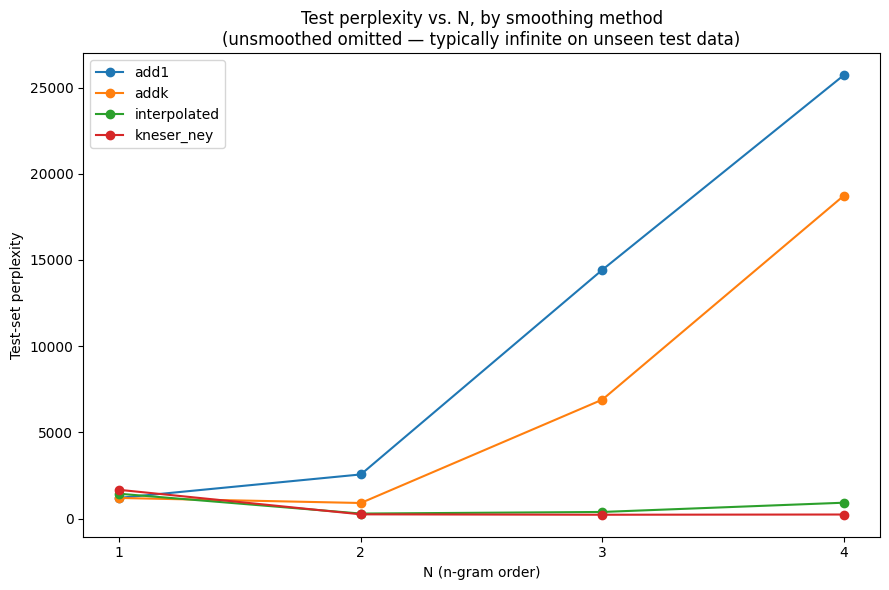

In [29]:

test_df_plot = results_df[results_df["split"] == "test"].copy()
finite_df = test_df_plot[np.isfinite(test_df_plot["perplexity"])]

fig, ax = plt.subplots(figsize=(9, 6))
for smoothing_name in ["add1", "addk", "interpolated", "kneser_ney"]:
    sub = finite_df[finite_df["smoothing"] == smoothing_name].sort_values("N")
    ax.plot(sub["N"], sub["perplexity"], marker="o", label=smoothing_name)
ax.set_xlabel("N (n-gram order)")
ax.set_ylabel("Test-set perplexity")
ax.set_xticks(N_VALUES)
ax.set_title("Test perplexity vs. N, by smoothing method\n(unsmoothed omitted — typically infinite on unseen test data)")
ax.legend()
plt.tight_layout()
plt.show()


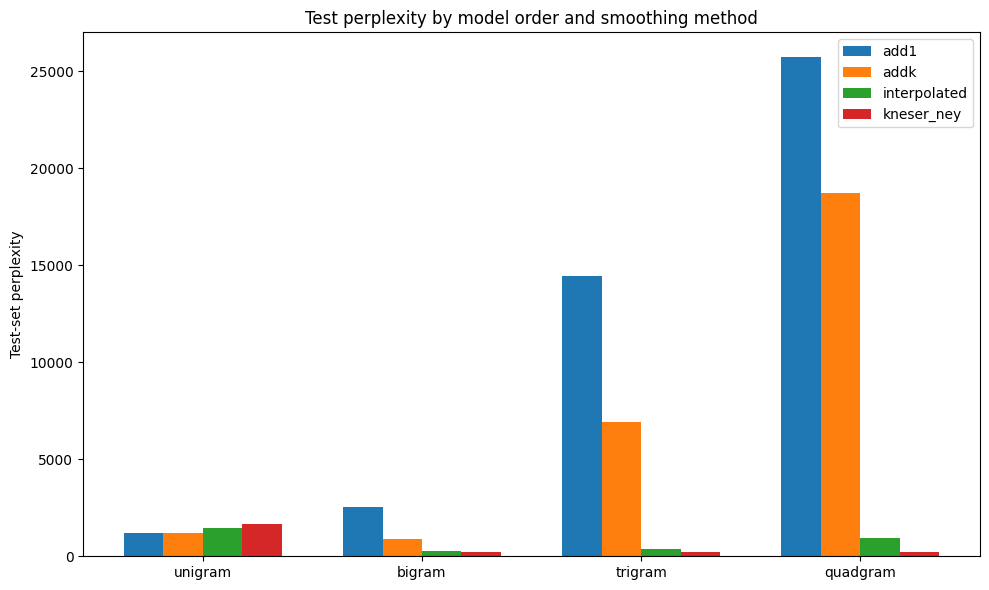

In [30]:

fig, ax = plt.subplots(figsize=(10, 6))
width = 0.18
smoothing_order = ["add1", "addk", "interpolated", "kneser_ney"]
x = np.arange(len(N_VALUES))

for i, smoothing_name in enumerate(smoothing_order):
    vals = []
    for n in N_VALUES:
        row = finite_df[(finite_df["N"] == n) & (finite_df["smoothing"] == smoothing_name)]
        vals.append(row["perplexity"].values[0] if len(row) else np.nan)
    ax.bar(x + i * width, vals, width, label=smoothing_name)

ax.set_xticks(x + width * (len(smoothing_order) - 1) / 2)
ax.set_xticklabels([NGRAM_NAMES[n] for n in N_VALUES])
ax.set_ylabel("Test-set perplexity")
ax.set_title("Test perplexity by model order and smoothing method")
ax.legend()
plt.tight_layout()
plt.show()


## 9. Qualitative check — next-word prediction examples

A quick sanity check: for a few dev-set sentence prefixes, show the top-5 most likely next words
under the best-performing model (typically trigram or quadgram + Kneser-Ney), to eyeball that
probabilities look linguistically reasonable.


In [31]:

def top_k_next_words(context_tokens, n, prob_fn, k=5, candidate_pool=None):
    # \"\"\"context_tokens: list of the last (n-1) words (already <unk>-mapped).
    # Returns top-k (word, prob) pairs.\"\"\"
    context = tuple(context_tokens[-(n - 1):]) if n > 1 else tuple()
    candidates = candidate_pool if candidate_pool is not None else VOCAB
    scored = []
    for w in candidates:
        ngram = context + (w,)
        scored.append((w, prob_fn(ngram, n)))
    scored.sort(key=lambda x: -x[1])
    return scored[:k]

# Restrict the candidate pool to words actually observed after some context in training,
# purely so this demo cell runs quickly (scoring the full ~V-size vocabulary per call is slow).
demo_candidates = list(VOCAB)[:2000] + [EOS]

BEST_N = 3
BEST_SMOOTHING = "kneser_ney"
best_prob_fn = SMOOTHING_FUNCS[BEST_SMOOTHING]

for sent in dev_sentences[:3]:
    toks = apply_unk(word_tokenize(sent))
    prefix = toks[: max(1, len(toks) // 2)]
    padded_prefix = ([BOS] * (BEST_N - 1) + prefix)
    print("PREFIX:", " ".join(prefix))
    top5 = top_k_next_words(padded_prefix, BEST_N, best_prob_fn, k=5, candidate_pool=demo_candidates)
    for w, p in top5:
        print(f"    {w!r:20s} P={p:.6f}")
    print()


PREFIX: स्थिति के लिए उदासी और लय के फिट बैठता है और जो लोग भारत में
    'प्रवेश'             P=0.008258
    'आप'                 P=0.005510
    'कम'                 P=0.003351
    '24'                 P=0.003033
    'रिलीज'              P=0.003032

PREFIX: इस तरह की क्षति की वजह से नस की अपूरणीय क्षति का मुंह देखना पड़ सकता है जिसे
    'आप'                 P=0.045933
    'की'                 P=0.004533
    'पूरी'               P=0.004106
    'अभियुक्त'           P=0.003952
    'काका'               P=0.003944

PREFIX: इस दौरान हमने 2 अरब
    'की'                 P=0.032543
    'जैसे'               P=0.001165
    '</s>'               P=0.001129
    'पूरी'               P=0.001126
    'युआन'               P=0.001055



## 10. Save results

In [32]:

RESULTS_DIR = Path("results")
RESULTS_DIR.mkdir(exist_ok=True)

results_df.to_csv(RESULTS_DIR / "ngram_perplexity_results_long.csv", index=False)
pivot_all.to_csv(RESULTS_DIR / "ngram_perplexity_results_pivot.csv")
test_pivot.to_csv(RESULTS_DIR / "ngram_perplexity_test_only.csv")

print("Saved:")
print(" -", RESULTS_DIR / "ngram_perplexity_results_long.csv")
print(" -", RESULTS_DIR / "ngram_perplexity_results_pivot.csv")
print(" -", RESULTS_DIR / "ngram_perplexity_test_only.csv")


Saved:
 - results/ngram_perplexity_results_long.csv
 - results/ngram_perplexity_results_pivot.csv
 - results/ngram_perplexity_test_only.csv


## 11. Summary / discussion (fill in after running)

Typical patterns to look for once this notebook has been executed end-to-end on the real 1M
sentence Hindi corpus:

- **Unsmoothed models**: perplexity on train is finite (often very low for high `N`, since the
  model has essentially memorized the training n-grams) but **explodes to infinity on dev/test**
  as soon as any unseen n-gram appears — worse the higher `N` is, since higher-order n-grams are
  sparser and more likely to be novel at test time.
- **Add-1 (Laplace)**: always finite, but for higher-order models the huge vocabulary size `V` in
  the denominator over-flattens the distribution, typically giving the **worst finite perplexity**
  among the smoothed methods, especially for trigrams/quadgrams.
- **Add-k** (`k=0.1`): less aggressive than add-1, usually **noticeably better perplexity** than
  Laplace since it doesn't over-penalize seen n-grams by adding a full pseudo-count.
- **Interpolated smoothing**: by backing off to lower-order (denser) distributions instead of a
  flat uniform, this typically **beats both Laplace and add-k**, especially for trigram/quadgram
  models where backing off to bigram/unigram evidence is very informative.
- **Kneser-Ney**: usually gives the **best (lowest) perplexity of all five methods**, particularly
  at higher `N`, because the continuation-probability backoff distribution is a better model of
  "how likely is this word to be a good continuation in a new context" than either a flat uniform
  or a raw-frequency-based backoff.
- **Effect of N**: for a fixed (good) smoothing method, perplexity generally **decreases from
  unigram → bigram → trigram**, then commonly **flattens out or slightly increases at quadgram**
  due to data sparsity — quadgram contexts are rare enough that even smoothing can't fully
  compensate, especially on a fixed 1M-sentence corpus.

Replace this cell with your own numeric observations (referencing the tables/plots in Sections 7–8)
once you've executed the notebook on your data.
